<a href="https://colab.research.google.com/github/adrianathaisnm-png/BA-Adriana-e-Ignacio/blob/main/Practica_centros_alumnado_v02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python en práctica: una red de centros deportivos
**MABA · Sesión 2 · Versión 02**

Trabajarás con **seis centros en Madrid, Barcelona y Valencia**, cuatro tipos de actividad y turnos de mañana y tarde. Cada centro ofrece tres tipos de actividad. Leerás archivos, consultarás Open-Meteo y unirás las fuentes para calcular y representar resultados.

El catálogo y la actividad son **datos sintéticos docentes**, preparados y completos. La meteorología es histórica y procede de Open-Meteo. Las coordenadas son referencias de cada ciudad, compartidas por sus dos centros; no corresponden a instalaciones reales. Las visitas cuentan asistencias a sesiones, no personas únicas.

## Cómo trabajar con las celdas
- Una celda de código **sin comentarios** está resuelta: ejecútala y observa su resultado.
- Si debes completar o cambiar código, encontrarás **`# MODIFICAR: ...`**, con la instrucción en mayúsculas. Cambia únicamente lo indicado. Los nombres exactos de variables y funciones aparecen en el enunciado; respeta sus minúsculas en Python.
- En las plantillas, sustituye los `None` o `pass`. Cuando esté resuelta la tarea, elimina también la línea `raise NotImplementedError(...)`, tal como indica su comentario. Esa línea señala una tarea pendiente.
- Las explicaciones y las preguntas están en las celdas de texto. Escribe tus respuestas donde aparece **Respuesta: …**.
- Ejecuta las celdas en orden. El notebook inicial tiene tareas pendientes; el completado debe poder ejecutarse entero.

La primera y la última respuesta son individuales y sin IA. Durante el desarrollo puedes consultar IA sobre fragmentos concretos; comprueba y explica las sugerencias que aceptes.

## Qué entregar
Notebook completado con salidas y respuestas, ZIP de resultados, enlace al repositorio y al commit final. El repositorio debe conservar una versión inicial y otra final del mismo notebook, las entradas y un README. Documenta dos decisiones de revisión con IA.

**Autores:** Adriana e Ignacio  **Repositorio:** https://github.com/adrianathaisnm-png/BA-Adriana-e-Ignacio

## 0. Entradas y diagnóstico
Descomprime el paquete. Abre el notebook en Google Colab, guarda una copia en Drive y conecta el entorno. Cuando se solicite, selecciona `actividad.csv` y `centros.xlsx` de la carpeta `datos`.

| Archivo | Campos | Qué representan |
|---|---|---|
| actividad.csv | actividad_id | Identificador único de una sesión deportiva. |
| actividad.csv | centro_id, fecha | Centro y día de la sesión. La fecha es un texto año-mes-día. |
| actividad.csv | actividad, turno | Tenis, Atletismo, Yoga o Entrenamiento funcional; Mañana o Tarde. |
| actividad.csv | duracion_min | Duración de la sesión, en minutos. |
| actividad.csv | plazas, visitas | Capacidad de la sesión y asistencias registradas. |
| centros.xlsx, hoja centros | centro_id, nombre, ciudad | Una fila por centro. |
| centros.xlsx | latitud, longitud | Coordenadas de referencia de su ciudad. |
| Open-Meteo | time, temperature_2m_max/min, precipitation_sum | Día, temperaturas máxima/mínima (°C) y precipitación (mm). |

Hay 504 sesiones: 14 días × 6 centros × 3 actividades por centro × 2 turnos. Las fechas vienen ya preparadas en el mismo formato que la API y se usarán directamente en la unión.

### Diagnóstico individual, antes de usar IA
1. ¿Qué representa una fila de actividad y una del catálogo? ¿Qué campo las relaciona?

una fila de actividad es una sesion/clase. y una fila del catalogo representa un centro y se relacionan con la variable del ID.

2. Si dos centros pertenecen a una ciudad, ¿cuántas consultas meteorológicas necesitas para esa ciudad?

solo una porque tienen las mismas coodenadas

3. Una sesión tiene 15 visitas y 20 plazas. ¿Cómo calcularías su porcentaje de ocupación?

15/20 *100

**Respuesta:** …

### Preparar bibliotecas
Importamos las herramientas de lectura, peticiones, cálculo y gráficos. `Path` permite construir rutas de archivos.

In [49]:
from pathlib import Path
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Cargar las entradas en Colab
Selecciona los dos archivos de datos a la vez. Repite la carga si inicias un entorno nuevo.

In [50]:
from google.colab import files

archivos_subidos = files.upload()

Saving actividad.csv to actividad (1).csv
Saving centros.xlsx to centros (1).xlsx


In [51]:
DATOS = Path('.')
SALIDAS = Path('salidas')
SALIDAS.mkdir(exist_ok=True)

### Versión inicial en GitHub
Crea un repositorio `practica-centros-python` con README. Desde Colab, usa **Archivo > Guardar una copia en GitHub**. Selecciona la rama y la ruta `practica_centros.ipynb`, con mensaje `Añade punto de partida de la práctica`. Conserva ese nombre y esa ruta para guardar la versión final.

Puedes usar un repositorio privado. No necesitas GitHub Desktop ni hacer push desde el ordenador.

## 1. Funciones y bucles
### R1. Revisar una función
Este fragmento muestra el porcentaje, pero no lo devuelve para reutilizarlo:
```python
def calcular_ocupacion(visitas, plazas):
    print(visitas / plazas * 100)
```
Completa la función con `return`. Prueba `calcular_ocupacion(15, 20)`: debe devolver 75.0. Las plazas de este ejercicio son siempre positivas.

In [52]:
def calcular_ocupacion(visitas, plazas):
    return visitas/plazas*100

calcular_ocupacion(15, 20)

    # MODIFICAR: DEVUELVE EL PORCENTAJE DE VISITAS SOBRE PLAZAS.

# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA CUANDO HAYAS COMPLETADO LA FUNCIÓN.
#raise NotImplementedError('R1')

75.0

### T1. Clasificar la ocupación
Define `clasificar_ocupacion(porcentaje)` con `if`, `elif`, `else` y `return`. Devuelve `Baja` si el porcentaje es menor que 50, `Media` si es menor que 80 y `Alta` en el resto de casos. Son categorías descriptivas del ejercicio. Comprueba los valores 40, 50 y 80.

In [53]:
def clasificar_ocupacion(porcentaje):
  if porcentaje <50:
    return"Baja"
  elif porcentaje <80:
    return"Media"
  else:
    return "Alta"


print (clasificar_ocupacion(40))
print (clasificar_ocupacion(50))
print (clasificar_ocupacion(80))

    # MODIFICAR: DEVUELVE BAJA, MEDIA O ALTA SEGÚN LOS UMBRALES DEL ENUNCIADO.
    #pass

# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA CUANDO HAYAS COMPLETADO LA FUNCIÓN.
#raise NotImplementedError('T1')

Baja
Media
Alta


### R2. Revisar un while
Lee este fragmento sin ejecutarlo: le falta avanzar el índice.
```python
turnos = ['Mañana', 'Tarde']
indice = 0
while indice < len(turnos):
    print(turnos[indice])
```
Completa el bucle para que muestre cada turno una sola vez y termine. **Respuesta:** ¿qué ocurre si el índice nunca cambia? QUE SERÍA SIEMPRE 0, Y EL BUCLE SERIA INFINITO

In [54]:
turnos = ['Mañana', 'Tarde']
indice = 0
while indice < len(turnos):
    print(turnos[indice])
    indice = indice + 1
# MODIFICAR: COMPLETA EL BUCLE WHILE Y AUMENTA EL ÍNDICE EN CADA VUELTA.
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA CUANDO HAYAS COMPLETADO EL BUCLE.
#raise NotImplementedError('R2')

Mañana
Tarde


## 2. Leer archivos y utilizar estructuras
### T2. CSV y Excel
Lee `actividad.csv` con `pd.read_csv` y `centros.xlsx` con `pd.read_excel`, indicando `sheet_name='centros'`. Usa las rutas `DATOS / 'actividad.csv'` y `DATOS / 'centros.xlsx'`.

In [55]:
# MODIFICAR: LEE EL CSV Y GUARDA SU TABLA EN LA VARIABLE INDICADA.
actividad_original = pd.read_csv(DATOS / 'actividad.csv')
# MODIFICAR: LEE EL EXCEL E INDICA LA HOJA DEL CATÁLOGO.
centros = pd.read_excel(DATOS / 'centros.xlsx', sheet_name='centros')
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA TRAS COMPLETAR LAS DOS LECTURAS.
#raise NotImplementedError('T2')




In [56]:
print(actividad_original.shape)
print(actividad_original.columns)
print(actividad_original.dtypes)
actividad_original.head()

(504, 8)
Index(['actividad_id', 'centro_id', 'fecha', 'actividad', 'turno',
       'duracion_min', 'plazas', 'visitas'],
      dtype='object')
actividad_id    object
centro_id       object
fecha           object
actividad       object
turno           object
duracion_min     int64
plazas           int64
visitas          int64
dtype: object


,actividad_id,centro_id,fecha,actividad,turno,duracion_min,plazas,visitas
0,ACT0001,C01,2026-09-01,Atletismo,Mañana,75,32,22
1,ACT0002,C01,2026-09-01,Atletismo,Tarde,75,32,20
2,ACT0003,C01,2026-09-01,Yoga,Mañana,45,24,14
3,ACT0004,C01,2026-09-01,Yoga,Tarde,45,24,19
4,ACT0005,C01,2026-09-01,Entrenamiento funcional,Mañana,60,20,10


In [57]:
actividad_original.info()
centros

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   actividad_id  504 non-null    object
 1   centro_id     504 non-null    object
 2   fecha         504 non-null    object
 3   actividad     504 non-null    object
 4   turno         504 non-null    object
 5   duracion_min  504 non-null    int64 
 6   plazas        504 non-null    int64 
 7   visitas       504 non-null    int64 
dtypes: int64(3), object(5)
memory usage: 31.6+ KB


,centro_id,nombre,ciudad,latitud,longitud
0,C01,Centro Retiro,Madrid,40.4168,-3.7038
1,C02,Centro Alameda,Madrid,40.4168,-3.7038
2,C03,Centro Litoral,Barcelona,41.3851,2.1734
3,C04,Centro Montjuïc,Barcelona,41.3851,2.1734
4,C05,Centro Turia,Valencia,39.4699,-0.3763
5,C06,Centro Malvarrosa,Valencia,39.4699,-0.3763


### Etiquetas y posiciones
Ejecuta los ejemplos. `loc` usa etiquetas y nombres de columnas; `iloc` usa posiciones. **Respuesta:** ¿qué devuelve cada celda? loc devuelve ACT0001 y C01. ILOC devuelve C01
Respuesta

In [58]:
actividad_original.loc[0, ['actividad_id', 'centro_id']]

,0
actividad_id,ACT0001
centro_id,C01


In [59]:
actividad_original.iloc[0, 1]  #Devuelve

'C01'

### T3. Listas, diccionarios, tuplas y conjuntos
`to_dict('records')` produce una lista de diccionarios, uno por centro. Completa una comprensión para obtener sus ciudades. Después utiliza `set` para obtener las ciudades distintas. Guarda las coordenadas del primer centro en una tupla y desempaquétala en `latitud` y `longitud`.

**Respuesta:** ¿por qué la lista tiene seis elementos y el conjunto solo tres? …. Respuesta: Porque los conjuntos no pueden tener valores repetidos.

In [60]:
centros_lista = centros.to_dict('records')
centros_lista

[{'centro_id': 'C01',
  'nombre': 'Centro Retiro',
  'ciudad': 'Madrid',
  'latitud': 40.4168,
  'longitud': -3.7038},
 {'centro_id': 'C02',
  'nombre': 'Centro Alameda',
  'ciudad': 'Madrid',
  'latitud': 40.4168,
  'longitud': -3.7038},
 {'centro_id': 'C03',
  'nombre': 'Centro Litoral',
  'ciudad': 'Barcelona',
  'latitud': 41.3851,
  'longitud': 2.1734},
 {'centro_id': 'C04',
  'nombre': 'Centro Montjuïc',
  'ciudad': 'Barcelona',
  'latitud': 41.3851,
  'longitud': 2.1734},
 {'centro_id': 'C05',
  'nombre': 'Centro Turia',
  'ciudad': 'Valencia',
  'latitud': 39.4699,
  'longitud': -0.3763},
 {'centro_id': 'C06',
  'nombre': 'Centro Malvarrosa',
  'ciudad': 'Valencia',
  'latitud': 39.4699,
  'longitud': -0.3763}]

In [61]:
# MODIFICAR: OBTÉN LA LISTA DE CIUDADES MEDIANTE UNA COMPRENSIÓN.
ciudades = [centro['ciudad'] for centro in centros_lista]

# MODIFICAR: CREA UN CONJUNTO A PARTIR DE LA LISTA DE CIUDADES.
ciudades_distintas = set(ciudades)

# MODIFICAR: CREA UNA TUPLA CON LATITUD Y LONGITUD DEL PRIMER CENTRO Y DESEMPAQUÉTALA.
coordenadas = (centros_lista[0]['latitud'], centros_lista[0]['longitud'])
latitud, longitud = coordenadas


print(ciudades)
print(ciudades_distintas)
print(latitud, longitud)

['Madrid', 'Madrid', 'Barcelona', 'Barcelona', 'Valencia', 'Valencia']
{'Valencia', 'Barcelona', 'Madrid'}
40.4168 -3.7038


## 3. Consultar la API
### T4. Petición y JSON
La función consulta los 14 días de una ciudad. Completa la petición con `requests.get(url, params=parametros, timeout=30)` y convierte `contenido['daily']` en una tabla con `pd.DataFrame`. Lee los parámetros y las unidades de la respuesta.

In [62]:
def consultar_meteo(ciudad, latitud, longitud):
    url = 'https://archive-api.open-meteo.com/v1/archive'
    variables = 'temperature_2m_max,temperature_2m_min,precipitation_sum'
    parametros = {
        'latitude': latitud,
        'longitude': longitud,
        'start_date': '2026-09-01',
        'end_date': '2026-09-14',
        'daily': variables,
        'timezone': 'Europe/Madrid'
    }
    # MODIFICAR: REALIZA LA PETICIÓN CON LA URL, LOS PARÁMETROS Y EL TIEMPO DE ESPERA INDICADOS.
    respuesta = requests.get(url, params=parametros, timeout=30)

    print(ciudad, respuesta.status_code)
    respuesta.raise_for_status()
    contenido = respuesta.json()
    print(contenido['daily_units'])
    # MODIFICAR: CONVIERTE EL DICCIONARIO DAILY EN UN DATAFRAME.
    tabla_ciudad = pd.DataFrame(contenido['daily'])
    tabla_ciudad = tabla_ciudad.rename(columns={'time': 'fecha'})
    tabla_ciudad['ciudad'] = ciudad
    return tabla_ciudad

### Una consulta por ciudad
El diccionario `ciudades_api` guarda unas coordenadas por ciudad. Los dos centros de cada ciudad comparten la referencia meteorológica. Asignar de nuevo la misma clave de un diccionario no crea otra entrada.

El `for` consulta cada ciudad y `append` añade su tabla a una lista. `concat` apila las tres tablas. El resultado tiene 42 filas: 3 ciudades × 14 días. Si la API no responde, el docente dispone de un respaldo para continuar.

In [63]:
ciudades_api = {}
for centro in centros_lista:
    ciudades_api[centro['ciudad']] = (centro['latitud'], centro['longitud'])

ciudades_api

{'Madrid': (40.4168, -3.7038),
 'Barcelona': (41.3851, 2.1734),
 'Valencia': (39.4699, -0.3763)}

In [64]:
tablas_meteo = []
for ciudad, coordenadas in ciudades_api.items():
    latitud, longitud = coordenadas
    tabla_ciudad = consultar_meteo(ciudad, latitud, longitud)
    tablas_meteo.append(tabla_ciudad)

meteo = pd.concat(tablas_meteo, ignore_index=True)
print(meteo.shape)
meteo.head()

Madrid 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
Barcelona 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
Valencia 200
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
(42, 5)


,fecha,temperature_2m_max,temperature_2m_min,precipitation_sum,ciudad
0,2026-09-01,34.2,19.7,0.0,Madrid
1,2026-09-02,35.3,18.6,0.0,Madrid
2,2026-09-03,37.6,20.4,0.0,Madrid
3,2026-09-04,38.6,21.5,0.0,Madrid
4,2026-09-05,35.9,24.2,0.9,Madrid


**Respuesta:** ¿qué contiene `daily`? R: Las variables extraidas de open meteo ¿Dónde aparecen las unidades? R:las unidades estarian en contenido['daily_units'] ¿Por qué la meteorología tiene menos filas que la actividad? …R:Porque meteorología está por ciudades y activida por centros.

## 4. Unir las fuentes y calcular nuevas columnas
### T5. Dos uniones
Completa dos `merge` con `how='left'`. Primero une `actividad_original` con `centros` mediante `centro_id`. Después une el resultado con `meteo` mediante `['ciudad', 'fecha']`.

La primera unión añade nombre, ciudad y coordenadas. La segunda añade los datos meteorológicos correspondientes al día y ciudad de cada sesión. Las claves de las tablas auxiliares identifican una sola fila. Las sesiones de un mismo día y ciudad comparten meteorología.

**Respuesta:** ¿por qué la segunda unión necesita tanto ciudad como fecha? … R: Porque meteorología depende de ciudad y fecha

In [65]:
# MODIFICAR: UNE LA ACTIVIDAD CON EL CATÁLOGO POR EL CÓDIGO DEL CENTRO.
preparada = actividad_original.merge(
    centros,
    on='centro_id',
    how='left'
    )
# MODIFICAR: UNE EL RESULTADO CON LA METEOROLOGÍA POR CIUDAD Y FECHA.
preparada=preparada.merge(
     meteo,
    on=['ciudad', 'fecha'],
    how='left'
)
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA TRAS COMPLETAR LAS DOS UNIONES.
#raise NotImplementedError('T5')

In [66]:
print('Sesiones antes de unir:', len(actividad_original))
print('Sesiones después de unir:', len(preparada))
preparada.head()

Sesiones antes de unir: 504
Sesiones después de unir: 504


,actividad_id,centro_id,fecha,actividad,turno,duracion_min,plazas,visitas,nombre,ciudad,latitud,longitud,temperature_2m_max,temperature_2m_min,precipitation_sum
0,ACT0001,C01,2026-09-01,Atletismo,Mañana,75,32,22,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
1,ACT0002,C01,2026-09-01,Atletismo,Tarde,75,32,20,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
2,ACT0003,C01,2026-09-01,Yoga,Mañana,45,24,14,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
3,ACT0004,C01,2026-09-01,Yoga,Tarde,45,24,19,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0
4,ACT0005,C01,2026-09-01,Entrenamiento funcional,Mañana,60,20,10,Centro Retiro,Madrid,40.4168,-3.7038,34.2,19.7,0.0


### T6. Ocupación y duración en horas
Utiliza `calcular_ocupacion` con las columnas `preparada['visitas']` y `preparada['plazas']`. La misma operación aritmética se aplica a cada fila. Guarda el resultado en `ocupacion_pct`. Divide `duracion_min` entre 60 y guarda `duracion_horas`.

La celda siguiente utiliza `apply` con la función de clasificación que has definido.

In [67]:
# MODIFICAR: CALCULA EL PORCENTAJE DE OCUPACIÓN CON LA FUNCIÓN DEFINIDA.
preparada['ocupacion_pct'] = calcular_ocupacion(
    preparada['visitas'],
    preparada['plazas']
)
# MODIFICAR: CONVIERTE LA DURACIÓN DE MINUTOS A HORAS.
preparada['duracion_horas'] = preparada['duracion_min'] / 60
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA TRAS COMPLETAR LOS DOS CÁLCULOS.
#rais#e NotImplementedError('T6')

In [68]:
preparada['nivel_ocupacion'] = preparada['ocupacion_pct'].apply(clasificar_ocupacion)
preparada[['actividad', 'turno', 'visitas', 'plazas', 'ocupacion_pct', 'nivel_ocupacion']].head()

,actividad,turno,visitas,plazas,ocupacion_pct,nivel_ocupacion
0,Atletismo,Mañana,22,32,68.750000,Media
1,Atletismo,Tarde,20,32,62.500000,Media
2,Yoga,Mañana,14,24,58.333333,Media
3,Yoga,Tarde,19,24,79.166667,Media
4,Entrenamiento funcional,Mañana,10,20,50.000000,Media


## 5. Resumir y visualizar
### NumPy y SciPy
La amplitud térmica es la máxima menos la mínima del día. La calculamos con arrays y obtenemos su media sobre la tabla de meteorología, donde cada ciudad-día aparece una vez.

`stats.iqr` devuelve la diferencia entre los percentiles 75 y 25. Aquí mide la dispersión de las visitas por sesión. Ejecuta y explica qué aportan la media, los cuartiles y el rango intercuartílico.
R: Se reciben de media 16 visitas por sesion. El 25% de las sesiones reciben 12 visitas o menos, el 50% de las sesiones reciben 15 visitas o menos y el 75% de las sesiones reciben 19,25 visitas o menos. Hay una dispersión de 7,25 visitas entre el primer y el tercer cuartil.

In [69]:
maximas = np.array(meteo['temperature_2m_max'])
minimas = np.array(meteo['temperature_2m_min'])
meteo['amplitud_termica'] = maximas - minimas
print('Amplitud térmica media (°C):', np.mean(meteo['amplitud_termica']))

Amplitud térmica media (°C): 10.83095238095238


In [70]:
print('Rango intercuartílico de visitas:', stats.iqr(preparada['visitas']))
preparada['visitas'].describe()

Rango intercuartílico de visitas: 7.25


,visitas
count,504.000000
mean,16.041667
std,5.515228
min,5.000000
25%,12.000000
50%,15.000000
75%,19.250000
max,36.000000


### T7. Agrupar por centro y por actividad y turno
Completa `resumen`, la suma de visitas por `nombre`, con `groupby` y `sum`. En `ocupacion_por_turno`, calcula la media de `ocupacion_pct` agrupando por `['actividad', 'turno']`.

La segunda tabla da el porcentaje medio por sesión: cada sesión pesa lo mismo. Si quisieras el porcentaje de todas las plazas ocupadas, el cálculo sería 100 × suma de visitas / suma de plazas.

**Respuesta:** ¿qué pregunta responde cada tabla? … R: resumen devuelve cuantas visitas ha recibido cada centro en total y ocupación por turno que porcentaje de ocupacion media tiene cada actividad por turno.

In [71]:
# MODIFICAR: SUMA LAS VISITAS AGRUPANDO POR EL NOMBRE DEL CENTRO.
resumen = preparada.groupby('nombre')['visitas'].sum()
# MODIFICAR: CALCULA LA OCUPACIÓN MEDIA POR TIPO DE ACTIVIDAD Y TURNO.
ocupacion_por_turno = ocupacion_por_turno = preparada.groupby(
    ['actividad', 'turno']
)['ocupacion_pct'].mean()
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA TRAS COMPLETAR LAS DOS AGRUPACIONES.
#raise NotImplementedError('T7')

### T8. Tabla dinámica
Construye `visitas_diarias` con `pivot_table`: `fecha` en filas, `ciudad` en columnas y suma de `visitas` como valores. La usaremos para representar tres series, una por ciudad.

In [72]:
# MODIFICAR: CREA LA TABLA DINÁMICA DE VISITAS POR FECHA Y CIUDAD.
visitas_diarias =preparada.pivot_table(
    index='fecha',
    columns='ciudad',
    values='visitas',
    aggfunc='sum'
)
# MODIFICAR: ELIMINA LA SIGUIENTE LÍNEA TRAS COMPLETAR LA TABLA.
#raise NotImplementedError('T8')

### T9. Gráficos con títulos y unidades
Completa los títulos y los nombres de los ejes. La primera figura representa el total diario de visitas por ciudad. La segunda muestra la distribución del porcentaje de ocupación por tipo de actividad y turno.

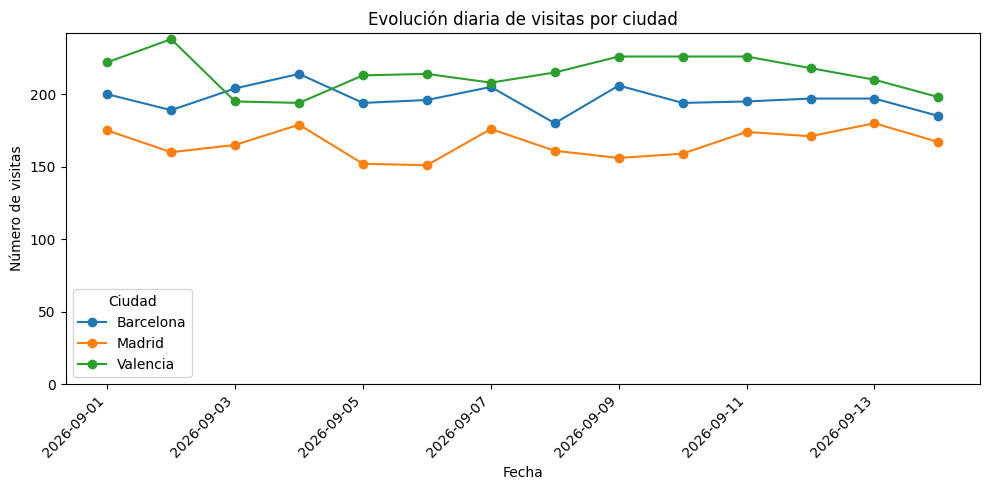

In [73]:
fig, ax = plt.subplots(figsize=(10, 5))
visitas_diarias.plot(ax=ax, marker='o')
# MODIFICAR: ESCRIBE UN TÍTULO QUE DESCRIBA EL GRÁFICO.
ax.set_title('Evolución diaria de visitas por ciudad')
# MODIFICAR: IDENTIFICA LA VARIABLE DEL EJE HORIZONTAL.
ax.set_xlabel('Fecha')
# MODIFICAR: IDENTIFICA LA VARIABLE Y UNIDAD DEL EJE VERTICAL.
ax.set_ylabel('Número de visitas')
ax.set_ylim(bottom=0)
ax.legend(title='Ciudad')
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
fig.savefig(SALIDAS / 'visitas_diarias.png', dpi=150)
plt.show()

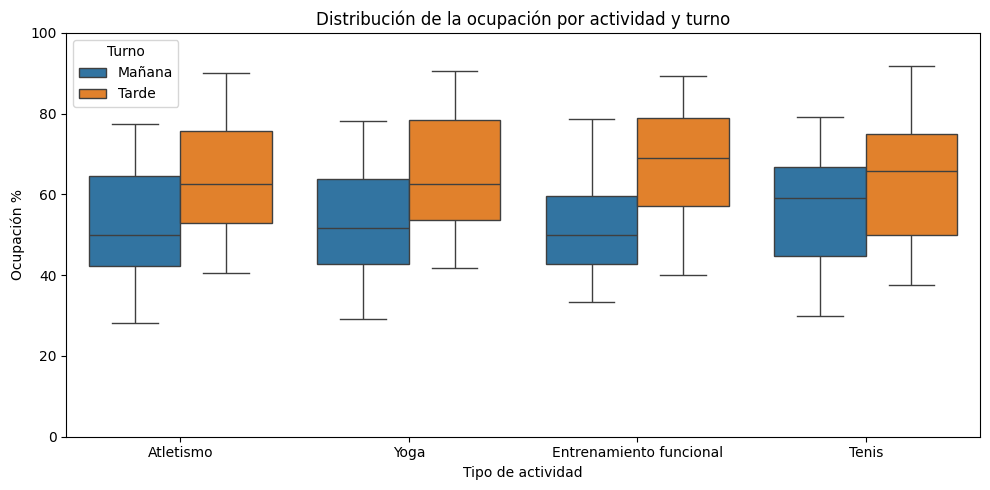

In [74]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=preparada, x='actividad', y='ocupacion_pct', hue='turno', ax=ax)
# MODIFICAR: ESCRIBE UN TÍTULO QUE DESCRIBA EL GRÁFICO.
ax.set_title('Distribución de la ocupación por actividad y turno')
# MODIFICAR: IDENTIFICA LA VARIABLE DEL EJE HORIZONTAL.
ax.set_xlabel('Tipo de actividad')
# MODIFICAR: IDENTIFICA LA VARIABLE Y UNIDAD DEL EJE VERTICAL.
ax.set_ylabel('Ocupación %')
ax.set_ylim(0, 100)
ax.legend(title='Turno')
fig.tight_layout()
fig.savefig(SALIDAS / 'ocupacion_actividad.png', dpi=150)
plt.show()

**Respuesta:** escribe una observación descriptiva de cada gráfico. Distingue visitas totales y porcentaje de ocupación. Explica por qué estos datos sintéticos no permiten atribuir a la meteorología cambios en la asistencia. …

R: En el primer gráfico, Valencia registra el mayor número total de visitas durante la mayoría de los días. En el segundo gráfico, la ocupación suele ser mayor por la tarde que por la mañana en todas las actividades, especialmente en entrenamiento funcional. Y al ser datos sintéticos, no podemos afirmar que la meteorología influya en la asistencia, ya que no se ha demostrado una relación causal entre ambas variables.

## 6. Revisar código con IA y guardar resultados
### Revisar una propuesta
Un asistente propone unir la meteorología solo mediante `ciudad`:
```python
preparada = actividad_original.merge(centros, on='centro_id', how='left')
preparada = preparada.merge(meteo, on='ciudad', how='left')
```
Lee la propuesta y compárala con T5. ¿Qué ocurre cuando una ciudad tiene 14 días meteorológicos? Explica por qué añadir `fecha` a la clave cambia el resultado. Puedes comprobarlo en una tabla temporal sin sustituir `preparada`.

R: Esto provocaría que una misma sesión apareciera repetida con distintas fechas meteorológicas pero al añadir la fecha de cada sesión se relaciona  con el registro meteorológico de su ciudad y fecha.

Después, solicita a la IA que revise una función o agrupación concreta. Dale el objetivo, las columnas y el fragmento. Comprueba su sugerencia antes de incorporarla.

| Decisión | Consulta y sugerencia | Qué aceptaste o cambiaste | Comprobación y resultado |
|---|---|---|---|
| 1 | … | … | … |
| 2 | … | … | … |

No hace falta entregar conversaciones completas.

| Decisión | Consulta y sugerencia | Qué aceptaste o cambiaste | Comprobación y resultado |
|---|---|---|---|
| 1 | Pedimos a la IA que revisara `clasificar_ocupacion`. Detectó que con `elif porcentaje > 80` el valor 80 se clasificaba como "media" y que las categorías estaban en minúscula. Sugirió usar `elif porcentaje < 80` y devolver `'Baja'`, `'Media'` y `'Alta'`. | Aceptamos los dos cambios, porque el enunciado indica que "Media" es para valores menores que 80 y que las categorías se escriben con mayúscula inicial. | Probamos la función con 40, 50 y 80 y devolvió Baja, Media y Alta. Al reejecutar el notebook, las 3 sesiones con un 80 % de ocupación pasaron a clasificarse como "Alta". |
| 2 | Pedimos a la IA que revisara `calcular_ocupacion`, porque la prueba no mostraba ningún resultado. Explicó que la llamada `calcular_ocupacion(15, 20)` estaba dentro de la función, después del `return`, y nunca se ejecutaba. Sugirió sacarla fuera de la función, sin sangría. | Aceptamos la sugerencia y movimos la llamada de prueba fuera de la función. | Al ejecutar la celda, la función devolvió 75.0, el resultado que pide el enunciado. |

### Exportar resultados
Se guarda la actividad enriquecida, la meteorología por ciudad-día, los resúmenes y los dos gráficos. Las entradas permanecen separadas.

In [75]:
preparada.to_csv(SALIDAS / 'actividad_preparada.csv', index=False)
meteo.to_csv(SALIDAS / 'meteo_diaria.csv', index=False)
resumen.to_csv(SALIDAS / 'resumen_centros.csv')
ocupacion_por_turno.to_csv(SALIDAS / 'ocupacion_por_turno.csv')
visitas_diarias.to_csv(SALIDAS / 'visitas_diarias.csv')

In [76]:
ficha = {
    'actividad': 'Datos sintéticos docentes MABA',
    'meteorologia': 'API histórica de Open-Meteo',
    'periodo': ['2026-09-01', '2026-09-14'],
    'ciudades': list(ciudades_api),
    'variables': 'temperature_2m_max,temperature_2m_min,precipitation_sum'
}
with open(SALIDAS / 'fuentes.json', 'w', encoding='utf-8') as archivo:
    json.dump(ficha, archivo, ensure_ascii=False, indent=2)

### Comprobación de resultados
Las uniones deben conservar las 504 sesiones. La suma de visitas debe coincidir en la entrada, la tabla preparada y los resúmenes. Revisa los títulos y las unidades de los gráficos y la fuente realmente utilizada.

In [77]:
print('Sesiones de entrada:', len(actividad_original))
print('Sesiones tras unir:', len(preparada))
print('Visitas de entrada:', actividad_original['visitas'].sum())
print('Visitas tras unir:', preparada['visitas'].sum())
print('Visitas del resumen:', resumen.sum())
print('Visitas de la tabla diaria:', visitas_diarias.sum().sum())

Sesiones de entrada: 504
Sesiones tras unir: 504
Visitas de entrada: 8085
Visitas tras unir: 8085
Visitas del resumen: 8085
Visitas de la tabla diaria: 8085


In [78]:
import shutil

shutil.make_archive('resultados_centros', 'zip', SALIDAS)
files.download('resultados_centros.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### README y versión final en GitHub
Completa la plantilla `README_plantilla.md` en el README de tu repositorio. Describe las fuentes, las entradas, los pasos para cargar archivos en Colab y las salidas. Registra las dos decisiones sobre IA.

Guarda el notebook desde Colab en **el mismo repositorio, rama y ruta `practica_centros.ipynb`** de la versión inicial. Usa un mensaje como `Completa funciones, uniones y resultados`. En GitHub, localiza el historial y explica una diferencia entre las dos versiones.

Guardar en Drive no actualiza GitHub. Guardar en GitHub tampoco incorpora los CSV de ejecución. Descarga el ZIP y adjúntalo a la entrega. Para reproducir el proyecto desde el repositorio, sube también el CSV y el Excel de entrada desde la web a una carpeta `datos`.

**Entrega:** enlace al repositorio, enlace al commit final y ZIP de resultados.

## 7. Comprobación individual final, sin IA
1. Explica una modificación de código, su propósito y cómo la comprobaste.

en la definicion de la siguiente funcion: clasificar_ocupacion(porcentaje)

cambiamos la redaccion del codigo porque el porcentaje 80, lo detectaba como "media", cuando era "alta"
y lo comprobamos con un print clasificar_ocupacion(80)

2. ¿Por qué tenemos 504 sesiones, 6 centros y 42 filas meteorológicas? ¿Qué representa una fila en cada caso?

Porque hay 14 días, 6 centros, 3 actividades por centro y 2 turnos. Las 6 filas del catálogo representan los 6 centros deportivos. Por último, tenemos 42 filas meteorológicas porque hay 3 ciudades y se recoge información de 14 días para cada una (3 × 14 = 42).

Cada fila representa los datos del tiempo deun dia de una ciudad.
3. Explica las claves de las dos uniones. ¿Por qué no basta con unir meteorología por ciudad?


las claves de las dos uniones son centro_id y para la segunda cuidad y fecha

No basta con unir por ciudad porque existen 14 registros meteorológicos por cada ciudad. Si solo uniéramos por ciudad, las sesiones se repetirían al relacionarse con todos los días meteorológicos, generando resultados incorrectos.

4. ¿Qué devuelven `calcular_ocupacion(18, 24)` y `clasificar_ocupacion(80)`? Explica cómo se obtienen.
devueven 75.0 y "Alta" respectivamente

18/24=75%
"Alta" se devuelve por la funcion que hicimos con if, elif y else

5. ¿Qué cambiarías en T7 para obtener visitas totales por turno?
Cambiaría la agrupación para utilizar la columna turno en lugar de nombre y sumaría la columna visitas. Asi tendria el acumulado


**Nombre y respuesta individual:** …

## Referencias
- [Open-Meteo: API histórica y variables](https://open-meteo.com/en/docs/historical-weather-api).
- [Requests: peticiones y respuestas](https://requests.readthedocs.io/en/latest/user/quickstart/).
- [pandas: merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html).
- [SciPy: rango intercuartílico](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.iqr.html).
- [Colab: archivos y entorno temporal](https://research.google.com/colaboratory/faq.html).

Los datos meteorológicos pueden revisarse en el servicio. Se comprueban estructura, fechas y unidades, sin exigir valores meteorológicos inmutables.